# Ejercicio 2: simulación de un único rayo binario

En este ejercicio se simulan rayos que seleccionan distintos píxeles de la imagen fantoma. Cada rayo queda determinado por una dirección $(\alpha,\beta)$ y un desplazamiento $s$, y selecciona los píxeles que cumplen la condición $\alpha i+\beta j=s$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## a) Construcción de la máscara de un rayo

La función `mascara_rayo` construye una matriz de $n\times n$ inicialmente llena de ceros. Luego recorre todos los píxeles y coloca un 1 en las posiciones $(i,j)$ que cumplen la condición $\alpha i+\beta j=s$. De esta manera, los unos indican los píxeles seleccionados por el rayo y los ceros representan los restantes.


In [2]:
def mascara_rayo(n, direccion, s):

    matriz = np.array([[0] * n for _ in range(n)])

    for i in range (0,n):
        for j in range (0, n):
            if (direccion[0]*i + direccion[1]*j == s):
                matriz [i,j] = 1

    return matriz

## b) Visualización de las máscaras

Se visualizan las máscaras correspondientes a las cinco combinaciones de dirección y desplazamiento indicadas. En cada imagen, los píxeles blancos, con valor 1, son los seleccionados por el rayo, mientras que los píxeles negros, con valor 0, no forman parte de su recorrido.


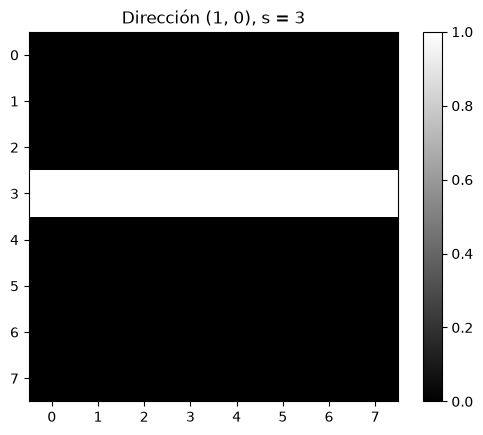

In [3]:
plt.imshow(mascara_rayo(8, (1,0), 3), cmap="gray")
plt.colorbar()
plt.title("Dirección (1, 0), s = 3")
plt.show()

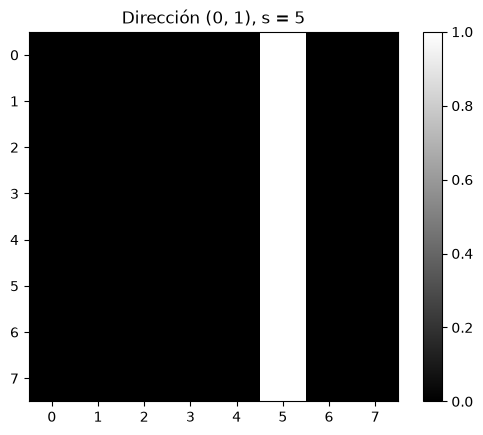

In [4]:
plt.imshow(mascara_rayo(8, (0,1), 5), cmap="gray")
plt.colorbar()
plt.title("Dirección (0, 1), s = 5")
plt.show()

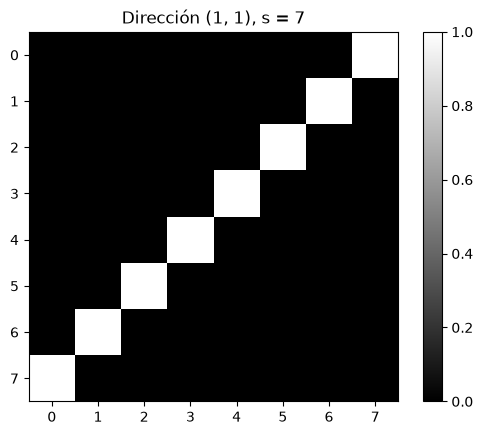

In [5]:
plt.imshow(mascara_rayo(8, (1,1), 7), cmap="gray")
plt.colorbar()
plt.title("Dirección (1, 1), s = 7")
plt.show()

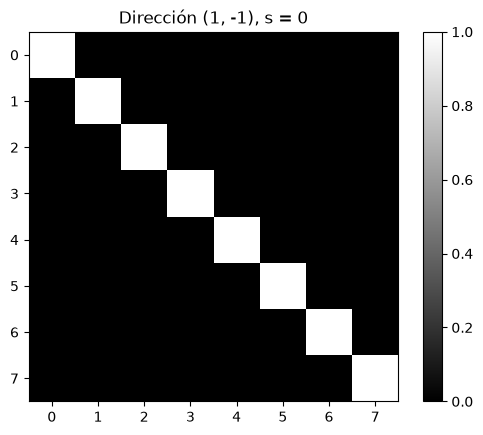

In [6]:
plt.imshow(mascara_rayo(8, (1,-1), 0), cmap="gray")
plt.colorbar()
plt.title("Dirección (1, -1), s = 0")
plt.show()

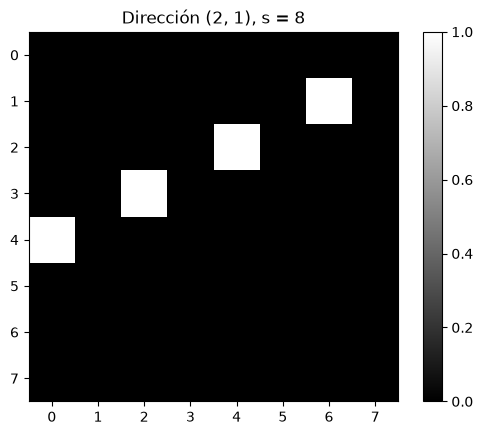

In [7]:
plt.imshow(mascara_rayo(8, (2,1), 8), cmap="gray")
plt.colorbar()
plt.title("Dirección (2, 1), s = 8")
plt.show()

## c) Cálculo de las mediciones

Para cada máscara se realiza el producto componente a componente con `X_fantoma`. Los ceros de la máscara eliminan los valores de los píxeles que no pertenecen al rayo, mientras que los unos conservan los valores de los píxeles seleccionados. Finalmente, estos valores se suman para obtener la medición $b_r$, que representa la atenuación total acumulada por el rayo.


In [8]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)


In [17]:
def mult_b_r (Mr):
    br = (Mr * X_fantoma).sum()
    return br

print (f"(1,0), s=3 -> {mult_b_r(mascara_rayo(8, (1,0), 3))}")
print (f"(0,1), s=5 -> {mult_b_r(mascara_rayo(8, (0,1), 5))}")
print (f"(1,1), s=7 -> {mult_b_r(mascara_rayo(8, (1,1), 7))}")
print (f"(1,-1), s=0 -> {mult_b_r(mascara_rayo(8, (1,-1), 0))}")
print (f"(2,1), s=8 -> {mult_b_r(mascara_rayo(8, (2,1), 8))}")


(1,0), s=3 -> 2.3
(0,1), s=5 -> 2.4
(1,1), s=7 -> 1.2
(1,-1), s=0 -> 1.9000000000000001
(2,1), s=8 -> 1.1


## d) Comparación entre las mediciones

Dos rayos con orientaciones diferentes pueden producir el mismo valor de medición aunque seleccionen distintos píxeles, porque cada medición conserva únicamente la suma de los valores atravesados. Distintos conjuntos de píxeles pueden tener la misma suma y, por lo tanto, producir el mismo valor de $b_r$. Una única medición no permite identificar por sí sola qué píxeles particulares generaron ese resultado.
